In [1]:
from pathlib import Path
import sys


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Could not find project root.")


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Street view assets directory
parent_path = project_root / "data" / "kriging_street_view"
sensor_locations_path = project_root / "data" / "spatial" / "sensor_locations.json"

# alivestreets is an external library for street-view collection and analysis.
# Install it separately if you need to re-run the collection pipeline.
# sys.path.append("/path/to/alivestreets/src")

from src.kriging.utils import get_bounding_box

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import json
import numpy as np

sensor_locations = pd.read_json(sensor_locations_path)
print(f"Loaded {len(sensor_locations)} sensor locations")

{'max_x': 234668.07235020146, 'min_x': 232762.5266563353, 'max_y': 899559.495289155, 'min_y': 898058.6852584648}


In [2]:
from utils import get_area_grid, get_square_dimensions

grid = get_area_grid(box, n_cells = 30)
width, height = get_square_dimensions(grid[0])
print(f"Each cell is {width} meters wide and {height} meters tall.")

Each cell is 63.518189795548096 meters wide and 50.02700102305971 meters tall.


<Axes: >

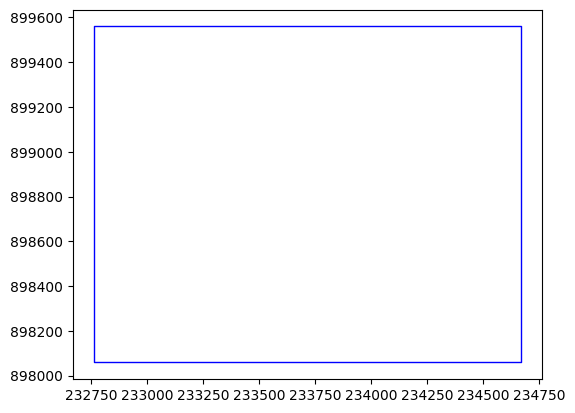

In [3]:
import geopandas as gpd


gdf = gpd.read_file(f"{parent_path}/bounding_box.geojson")
gdf.plot(facecolor ="none", edgecolor = "blue")

In [ ]:
# alivestreets: external library for street-view collection and feature extraction.
# Install separately to use this notebook: pip install alivestreets
# Uncomment the imports below once installed.
#
# import sys
# sys.path.append("/path/to/alivestreets/src")
# from alivestreets.features.facade_features import FacadeFeatureExtractor

In [5]:
import numpy as np
from shapely.geometry import Point, LineString

square = gdf.geometry.iloc[0]
center = square.centroid

corners = list(square.exterior.coords)[:-1]
corner_distances = [center.distance(Point(x, y)) for x, y in corners]
radius_to_corner = max(corner_distances)


side_midpoints = []
coords = corners + [corners[0]]
for i in range(4):
    p1, p2 = coords[i], coords[i + 1]
    side_midpoints.append(LineString([p1, p2]).interpolate(0.5, normalized=True))

midpoint_distances = [center.distance(mp) for mp in side_midpoints]
radius_to_side_midpoint = max(midpoint_distances)  

print("center (projected):", (center.x, center.y))
print("radius corner:", radius_to_corner)
print("radius side midpoint:", radius_to_side_midpoint)

center (projected): (233715.29950326838, 898809.0902738097)
radius corner: 1212.7999772874168
radius side midpoint: 952.7728469330759


<Axes: >

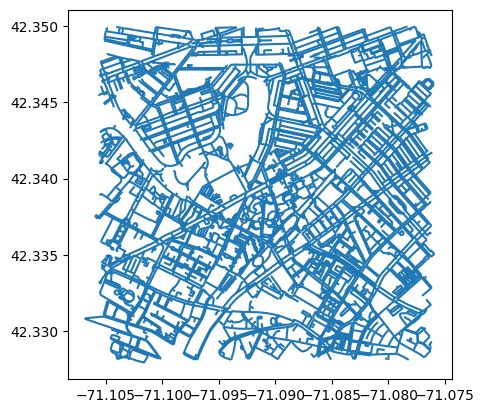

In [6]:

import geopandas as gpd
gdf_network = gpd.read_file(parent_path/"network/network.geojson")
gdf_network.plot()


6231


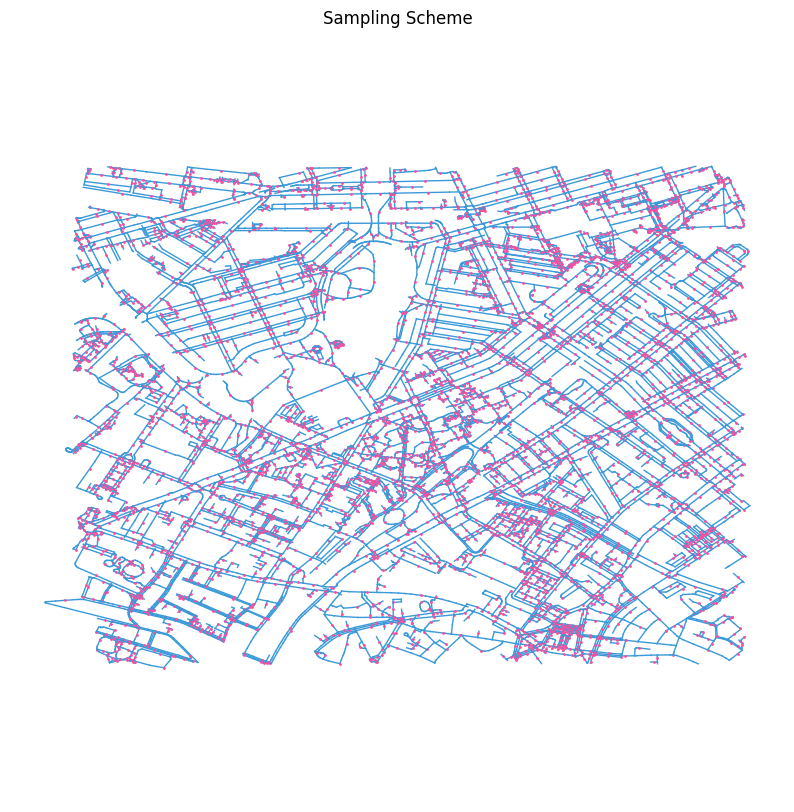

In [7]:
n_sampling_points = 1000
street_sampler = StreetSampler(n_sampling_points)

street_sampler.open_streets(parent_path/"network/network.geojson")
street_sampler.sample_streets_no_intersections()
street_sampler.draw_sampling_scheme()

print(len(street_sampler.get_all_sampling_points()))

In [8]:
# Load already-collected point dictionaries
point_dictionaries_path = parent_path / "streetview_images" / "point_dictionaries.jsonl"

point_dicts = [json.loads(line) for line in open(point_dictionaries_path)]
print(f"Loaded {len(point_dicts)} point dictionaries")

In [35]:
from concurrent.futures import ThreadPoolExecutor
import os
import threading

import numpy as np
from PIL import Image
from tqdm import tqdm

from alivestreets.features.facade_features import FacadeFeatureExtractor

n_cars = []
sky_ratios = []
facade_areas = []
road_ratios = []

input_feature_names = ["facade", "sky", "road", "vehicle"]
confidence_threshold = 0.2
_thread_local = threading.local()


def _get_extractor():
    if not hasattr(_thread_local, "extractor"):
        extractor = FacadeFeatureExtractor()
        extractor.download_model()
        _thread_local.extractor = extractor
    return _thread_local.extractor


def _mask_ratio(masks):
    if not masks:
        return 0.0
    final_mask = np.logical_or.reduce(masks)
    return float(np.mean(final_mask))


def _compute_view_metrics(view_path):
    if not os.path.exists(view_path):
        return None

    try:
        with Image.open(view_path) as img:
            image = np.array(img)
    except Exception:
        return None

    extractor = _get_extractor()

    vehicle_masks, _ = extractor.get_masks(
        image,
        class_name="vehicle",
        confidence_threshold=confidence_threshold,
    )
    sky_masks, _ = extractor.get_masks(
        image,
        class_name="sky",
        confidence_threshold=0.0,
    )
    road_masks, _ = extractor.get_masks(
        image,
        class_name="road",
        confidence_threshold=confidence_threshold,
    )
    facade_masks, _ = extractor.get_masks(
        image,
        class_name="facade",
        confidence_threshold=confidence_threshold,
    )

    return (
        len(vehicle_masks),
        _mask_ratio(sky_masks),
        _mask_ratio(road_masks),
        _mask_ratio(facade_masks),
    )


def _compute_point_metrics(point):
    view_paths = point.get("view_paths", [])
    n_views = len(view_paths)
    if n_views == 0:
        return None, None, None, None

    n_cars_point = 0
    sky_ratio_point = 0.0
    road_ratio_point = 0.0
    facade_area_point = 0.0

    for view_path in view_paths:
        metrics = _compute_view_metrics(view_path)
        #print(f"Processed {metrics}")
        if metrics is None:
            return None, None, None, None

        cars, sky, road, facade = metrics
        n_cars_point += cars
        sky_ratio_point += sky / n_views
        road_ratio_point += road / n_views
        facade_area_point += facade / n_views

    return n_cars_point, sky_ratio_point, road_ratio_point, facade_area_point


max_workers = min(4, os.cpu_count() or 1)

with ThreadPoolExecutor(max_workers=max_workers) as executor:
    point_metrics = list(tqdm(executor.map(_compute_point_metrics, data_points), total=len(data_points)))
    

for n_cars_point, sky_ratio_point, road_ratio_point, facade_area_point in point_metrics:
    n_cars.append(n_cars_point)
    sky_ratios.append(sky_ratio_point)
    road_ratios.append(road_ratio_point)
    facade_areas.append(facade_area_point)

  0%|          | 0/6228 [00:00<?, ?it/s]


Model already exists. Loaded existing model.
Facade feature ID dictionary:
bench: 0
door: 1
facade: 2
graffiti: 3
person: 4
road: 5
sidewalk: 6
signage: 7
sky: 8
street light: 9
trash: 10
utility pole: 11
vegetation: 12
vehicle: 13
window: 14
Model already exists. Loaded existing model.
Facade feature ID dictionary:
bench: 0
door: 1
facade: 2
graffiti: 3
person: 4
road: 5
sidewalk: 6
signage: 7
sky: 8
street light: 9
trash: 10
utility pole: 11
vegetation: 12
vehicle: 13
window: 14
Model already exists. Loaded existing model.
Facade feature ID dictionary:
bench: 0
door: 1
facade: 2
graffiti: 3
person: 4
road: 5
sidewalk: 6
signage: 7
sky: 8
street light: 9
trash: 10
utility pole: 11
vegetation: 12
vehicle: 13
window: 14
Model already exists. Loaded existing model.
Facade feature ID dictionary:
bench: 0
door: 1
facade: 2
graffiti: 3
person: 4
road: 5
sidewalk: 6
signage: 7
sky: 8
street light: 9
trash: 10
utility pole: 11
vegetation: 12
vehicle: 13
window: 14


100%|██████████| 6228/6228 [1:52:18<00:00,  1.08s/it]  


In [39]:

# Tag all 4 computed features onto street segments
street_sampler.tag_streets("n_cars", n_cars)
street_sampler.tag_streets("sky_ratio", sky_ratios)
street_sampler.tag_streets("road_ratio", road_ratios)
street_sampler.tag_streets("facade_area", facade_areas)

from alivestreets.sampling.geojson_sampler_exporter import StreetSamplerGeojsonExporter

exporter = StreetSamplerGeojsonExporter(street_sampler)
export_path = parent_path / "tagged_streets_4_features.geojson"
exporter.export(export_path)

6231
6228


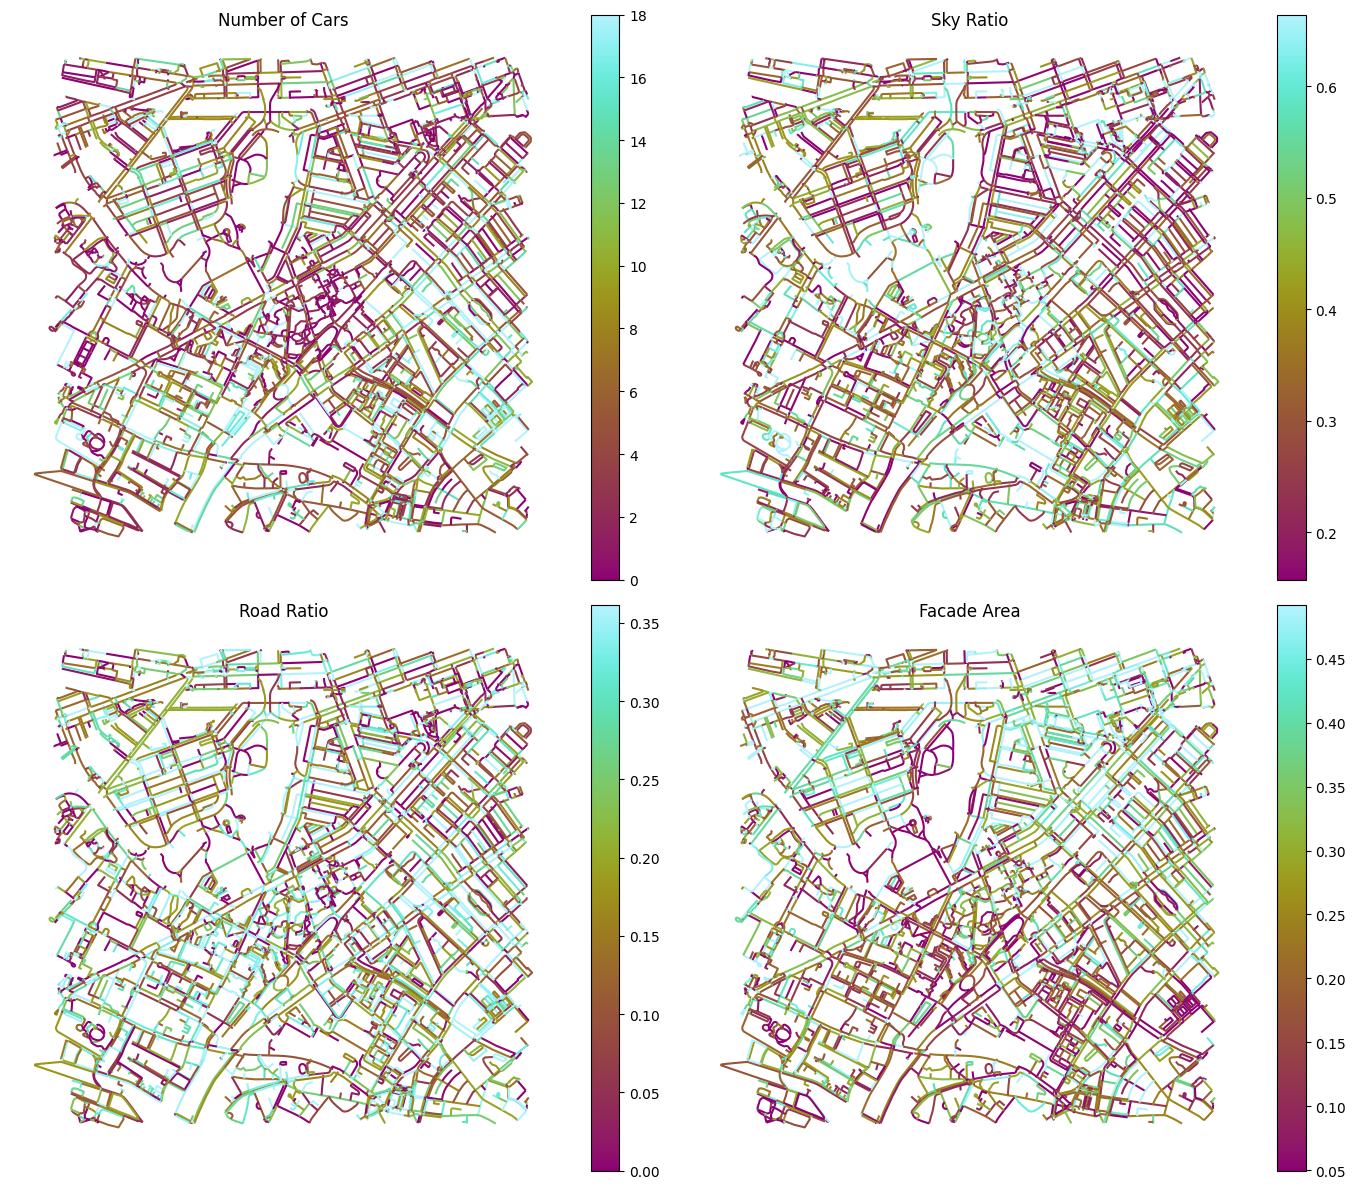

In [48]:

import geopandas as gpd
import cmcrameri.cm as cmc
import matplotlib.pyplot as plt

gdf_features = gpd.read_file(export_path)

feature_specs = [
    ("n_cars", "Number of Cars", cmc.hawaii),
    ("sky_ratio", "Sky Ratio", cmc.hawaii),
    ("road_ratio", "Road Ratio", cmc.hawaii),
    ("facade_area", "Facade Area", cmc.hawaii),
]

min_percentile = 10
max_percentile = 90

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (col, title, cmap) in zip(axes, feature_specs):
    min_value = gdf_features[col].quantile(min_percentile / 100)
    max_value = gdf_features[col].quantile(max_percentile / 100)
    clipped_col = f"{col}_clipped"
    gdf_features[clipped_col] = gdf_features[col].clip(lower=min_value, upper=max_value)

    gdf_features.plot(column=clipped_col, legend=True, cmap=cmap, ax=ax)
    ax.set_axis_off()
    ax.set_title(title)

plt.tight_layout()

Text(0.5, 1.0, 'Grid-aggregated Sky Ratio (median)')

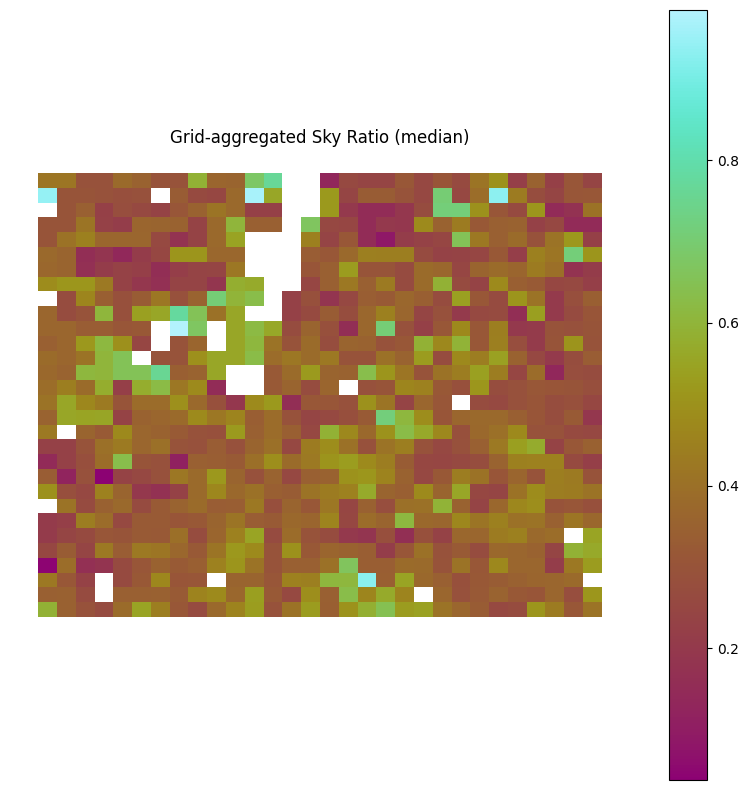

In [43]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

# Inputs
gdf_features = gpd.read_file(export_path)  # tagged street network (LineString)
grid = gpd.read_file(parent_path / "grid_rectangles.geojson")

# 1) Ensure same CRS
if gdf_features.crs != grid.crs:
    gdf_features = gdf_features.to_crs(grid.crs)

feature_cols = ["n_cars", "sky_ratio", "road_ratio", "facade_area"]

streets = gdf_features[feature_cols + ["geometry"]].copy()
grid_ix = grid.reset_index(names="grid_id")[["grid_id", "geometry"]]

# 2) Split streets by grid cell intersections
parts = gpd.overlay(streets, grid_ix, how="intersection")

# 3) Length-weighted aggregation per grid cell for all features
parts["seg_len"] = parts.geometry.length

agg_dict = {
    "n_segments": ("seg_len", "count"),
    "total_len": ("seg_len", "sum"),
}

for col in feature_cols:
    parts[f"{col}_len"] = parts[col] * parts["seg_len"]
    agg_dict[f"{col}_mean"] = (col, "mean")
    agg_dict[f"{col}_median"] = (col, "median")
    agg_dict[f"{col}_std"] = (col, "std")
    agg_dict[f"{col}_len_sum"] = (f"{col}_len", "sum")

agg = parts.groupby("grid_id").agg(**agg_dict).reset_index()

for col in feature_cols:
    agg[f"{col}_mean_weighted"] = agg[f"{col}_len_sum"] / agg["total_len"]
    agg = agg.drop(columns=[f"{col}_len_sum"])

# 4) Attach aggregated values back to the grid
grid_agg = grid_ix.merge(agg, on="grid_id", how="left").merge(
    grid.drop(columns="geometry"), left_on="grid_id", right_index=True, how="left"
)
grid_agg = gpd.GeoDataFrame(grid_agg, geometry="geometry", crs=grid.crs)


# After grid_agg is created
feature_cols = ["n_cars", "sky_ratio", "road_ratio", "facade_area"]

# Common columns you may want in every export
base_cols = ["grid_id", "geometry", "n_segments", "total_len"]

grid_agg_by_feature = {}

for col in feature_cols:
    cols = base_cols + [
        f"{col}_mean",
        f"{col}_median",
        f"{col}_std",
        f"{col}_mean_weighted",
    ]
    gdf_feature = grid_agg[cols].copy()
    grid_agg_by_feature[col] = gdf_feature

    out_path = parent_path / f"grid_aggregated_{col}.geojson"
    gdf_feature.to_file(out_path, driver="GeoJSON")

# Example plot: median sky ratio by grid cell
fig, ax = plt.subplots(figsize=(10, 10))
grid_agg_by_feature["sky_ratio"].plot(column="sky_ratio_median", cmap=cmc.hawaii, legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Grid-aggregated Sky Ratio (median)")

<Axes: >

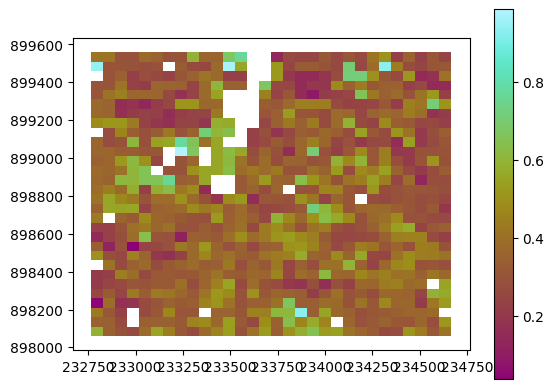

In [44]:
gdf_sky_ratio = grid_agg_by_feature["sky_ratio"]
gdf_sky_ratio.plot(column="sky_ratio_median", cmap=cmc.hawaii, legend=True)

<Axes: >

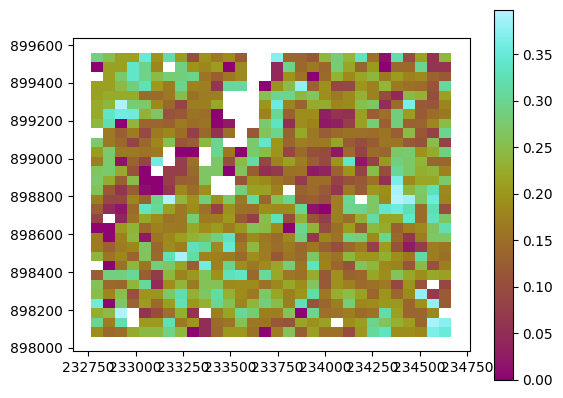

In [45]:
gdf_road = grid_agg_by_feature["road_ratio"]
gdf_road.plot(column="road_ratio_median", cmap=cmc.hawaii, legend=True)

<Axes: >

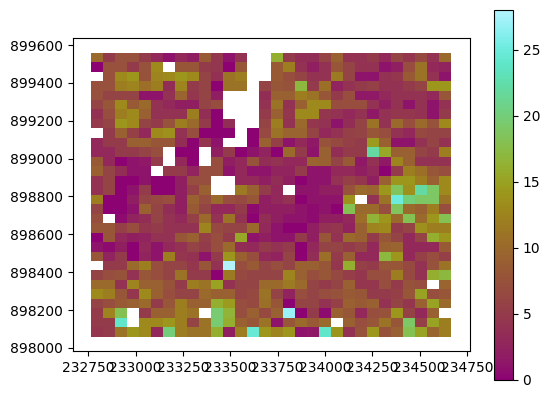

In [46]:
gdf_cars = grid_agg_by_feature["n_cars"]
gdf_cars.plot(column="n_cars_median", cmap=cmc.hawaii, legend=True)

<Axes: >

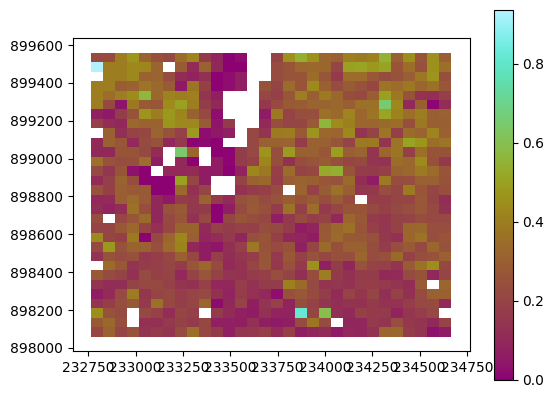

In [49]:
gdf_facade_area = grid_agg_by_feature["facade_area"]
gdf_facade_area.plot(column="facade_area_median", cmap=cmc.hawaii, legend=True)